In [2]:
import pandas as pd

df = pd.read_csv("AB_NYC_2019.csv")

display(df.head())


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [3]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 48895
Total Columns: 16


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

In [5]:
missing_values = df.isnull().sum()

display(missing_values.to_frame(name="Missing Values"))

,Missing Values
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [6]:

# Check missing review information

print("Listings with zero reviews:")
print((df["number_of_reviews"] == 0).sum())

print("\nMissing last_review with zero reviews:")
print(
    df.loc[
        df["last_review"].isna(),
        "number_of_reviews"
    ].value_counts()
)

print("\nMissing reviews_per_month with zero reviews:")
print(
    df.loc[
        df["reviews_per_month"].isna(),
        "number_of_reviews"
    ].value_counts()
)


Listings with zero reviews:
10052

Missing last_review with zero reviews:
number_of_reviews
0    10052
Name: count, dtype: int64

Missing reviews_per_month with zero reviews:
number_of_reviews
0    10052
Name: count, dtype: int64


In [7]:

df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)


Original Dataset: (48895, 16)
Working Dataset: (48895, 16)


In [8]:

df_clean["name"] = df_clean["name"].fillna("Unknown Listing")

df_clean["host_name"] = df_clean["host_name"].fillna("Unknown Host")


In [9]:

missing_reviews = df_clean["reviews_per_month"].isna()

print(
    df_clean.loc[missing_reviews, "number_of_reviews"].value_counts()
)


number_of_reviews
0    10052
Name: count, dtype: int64


In [10]:

df_clean.loc[
    (df_clean["number_of_reviews"] == 0)
    & (df_clean["reviews_per_month"].isna()),
    "reviews_per_month"
] = 0


In [11]:

df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"],
    errors="coerce"
)

print(df_clean["last_review"].dtype)


datetime64[us]


In [12]:

print("Missing Values After Cleaning:")

display(
    df_clean.isnull().sum().to_frame("Missing Values")
)

print("Dataset Shape:", df_clean.shape)


Missing Values After Cleaning:


,Missing Values
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


Dataset Shape: (48895, 16)


In [13]:

print("Total Duplicate Rows:", df_clean.duplicated().sum())

print("Duplicate Listing IDs:", df_clean["id"].duplicated().sum())


Total Duplicate Rows: 0
Duplicate Listing IDs: 0


In [14]:

duplicate_listings = df_clean[
    df_clean.duplicated(subset=["id"], keep=False)
]

display(duplicate_listings.sort_values("id"))


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365


In [15]:

print("Airbnb Price Statistics:")

display(df_clean["price"].describe())

print("\nZero Price Listings:",
      (df_clean["price"] == 0).sum())

print("Negative Price Listings:",
      (df_clean["price"] < 0).sum())


Airbnb Price Statistics:


count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


Zero Price Listings: 11
Negative Price Listings: 0


Matplotlib is building the font cache; this may take a moment.


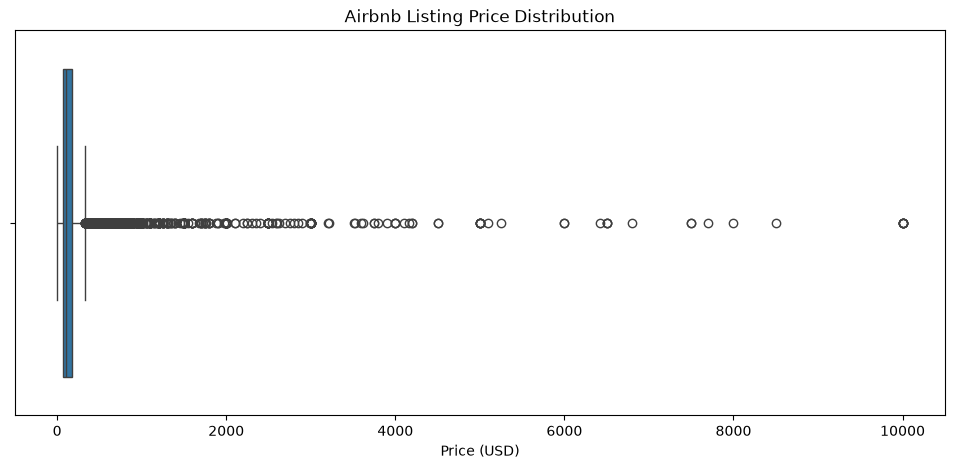

In [16]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.boxplot(x=df_clean["price"])

plt.title("Airbnb Listing Price Distribution")
plt.xlabel("Price (USD)")
plt.show()


In [17]:

# Calculate price quartiles

Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)


Q1: 69.0
Q3: 175.0
IQR: 106.0
Lower Bound: -90.0
Upper Bound: 334.0


In [18]:

# Identify price outliers

outliers = df_clean[
    (df_clean["price"] < lower_bound) |
    (df_clean["price"] > upper_bound)
]

print("Total Outliers:", len(outliers))

print(
    "Outlier Percentage:",
    round(len(outliers) / len(df_clean) * 100, 2),
    "%"
)

display(
    outliers[
        ["name", "neighbourhood_group", "room_type", "price"]
    ].head(10)
)


Total Outliers: 2972
Outlier Percentage: 6.08 %


,name,neighbourhood_group,room_type,price
61,Sunny & Spacious Chelsea Apartment,Manhattan,Entire home/apt,375
85,perfect for a family or small group,Brooklyn,Entire home/apt,800
103,2000 SF 3br 2bath West Village private townhouse,Manhattan,Entire home/apt,500
114,2 BR / 2 Bath Duplex Apt with patio! East Village,Manhattan,Entire home/apt,350
121,3 Story Town House in Park Slope,Brooklyn,Entire home/apt,400
158,Luxury Brownstone in Boerum Hill,Brooklyn,Entire home/apt,475
181,Beautiful Queens Brownstone! - 5BR,Queens,Entire home/apt,350
233,"Beautiful, elegant 3 bed SOHO loft",Manhattan,Entire home/apt,500
242,Huge Chelsea Loft,Manhattan,Entire home/apt,500
263,Cottage in the Village,Manhattan,Entire home/apt,390


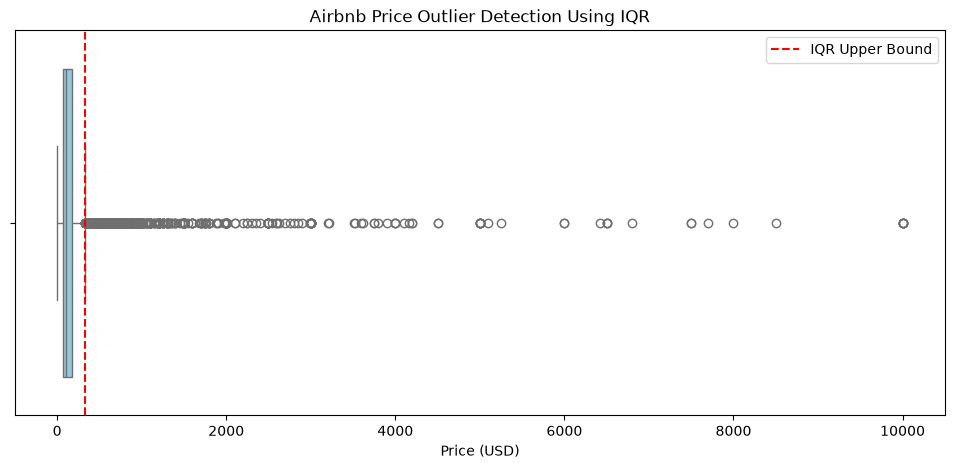

In [19]:

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df_clean,
    x="price",
    color="skyblue"
)

plt.axvline(
    upper_bound,
    color="red",
    linestyle="--",
    label="IQR Upper Bound"
)

plt.title("Airbnb Price Outlier Detection Using IQR")
plt.xlabel("Price (USD)")
plt.legend()
plt.show()


In [20]:

# Check invalid prices before cleaning
invalid_prices = (df_clean["price"] <= 0).sum()

print("Invalid Price Listings:", invalid_prices)

# Keep only listings with positive prices
df_clean = df_clean[df_clean["price"] > 0].copy()

print("Remaining Listings:", len(df_clean))


Invalid Price Listings: 11
Remaining Listings: 48884


In [21]:

# Flag potential price outliers

df_clean["price_outlier"] = (
    (df_clean["price"] < lower_bound) |
    (df_clean["price"] > upper_bound)
)

print("Potential Price Outliers:")
print(df_clean["price_outlier"].value_counts())


Potential Price Outliers:
price_outlier
False    45912
True      2972
Name: count, dtype: int64


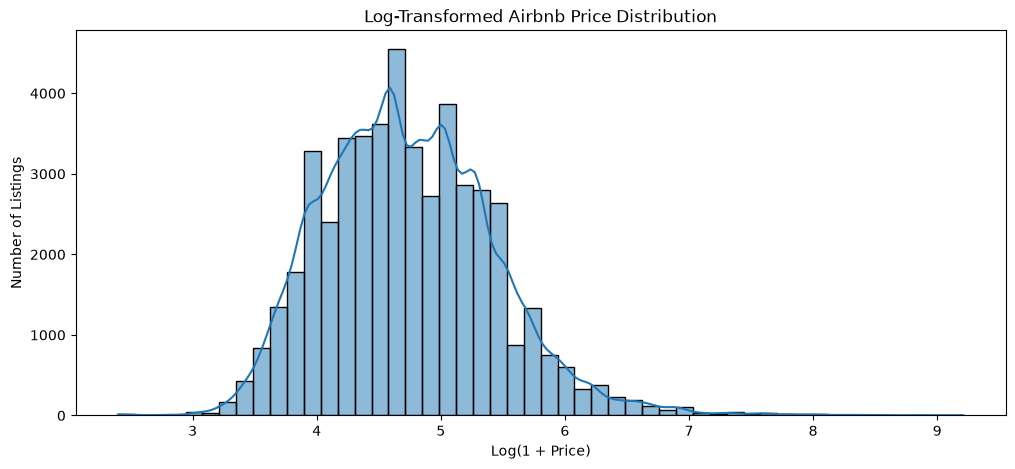

In [22]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.histplot(
    np.log1p(df_clean["price"]),
    bins=50,
    kde=True
)

plt.title("Log-Transformed Airbnb Price Distribution")
plt.xlabel("Log(1 + Price)")
plt.ylabel("Number of Listings")

plt.show()


In [23]:

print("Cleaned Dataset Shape:", df_clean.shape)

print("Minimum Price:", df_clean["price"].min())
print("Maximum Price:", df_clean["price"].max())

print("Remaining Missing Values:")
display(df_clean.isnull().sum())


Cleaned Dataset Shape: (48884, 17)
Minimum Price: 10
Maximum Price: 10000
Remaining Missing Values:


id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10051
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
price_outlier                         0
dtype: int64

In [24]:

columns = [
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_365",
    "calculated_host_listings_count"
]

display(
    df_clean[columns].describe().T
)


,count,mean,std,min,25%,50%,75%,max
minimum_nights,48884.0,7.029887,20.512224,1.0,1.00,3.00,5.00,1250.0
number_of_reviews,48884.0,23.271991,44.551331,0.0,1.00,5.00,24.00,629.0
reviews_per_month,48884.0,1.090800,1.597213,0.0,0.04,0.37,1.58,58.5
availability_365,48884.0,112.779498,131.627271,0.0,0.00,45.00,227.00,365.0
calculated_host_listings_count,48884.0,7.144628,32.956185,1.0,1.00,1.00,2.00,327.0


In [25]:

print(
    "Invalid minimum nights:",
    (df_clean["minimum_nights"] < 1).sum()
)

print(
    "Invalid availability:",
    (
        (df_clean["availability_365"] < 0) |
        (df_clean["availability_365"] > 365)
    ).sum()
)

print(
    "Negative reviews:",
    (df_clean["number_of_reviews"] < 0).sum()
)

print(
    "Negative monthly review rate:",
    (df_clean["reviews_per_month"] < 0).sum()
)

print(
    "Invalid host listing count:",
    (df_clean["calculated_host_listings_count"] < 1).sum()
)



Invalid minimum nights: 0
Invalid availability: 0
Negative reviews: 0
Negative monthly review rate: 0
Invalid host listing count: 0


In [26]:

df_clean["has_reviews"] = (
    df_clean["number_of_reviews"] > 0
).astype(int)

print(df_clean["has_reviews"].value_counts())


has_reviews
1    38833
0    10051
Name: count, dtype: int64


In [27]:

import numpy as np

df_clean["host_category"] = pd.cut(
    df_clean["calculated_host_listings_count"],
    bins=[0, 1, 5, 20, np.inf],
    labels=[
        "Single Listing",
        "Small Host",
        "Medium Host",
        "Large Host"
    ]
)

display(df_clean["host_category"].value_counts())


host_category
Single Listing    32301
Small Host        11792
Medium Host        2586
Large Host         2205
Name: count, dtype: int64

In [28]:

df_clean["availability_category"] = pd.cut(
    df_clean["availability_365"],
    bins=[-1, 0, 90, 180, 365],
    labels=[
        "Unavailable",
        "Low Availability",
        "Medium Availability",
        "High Availability"
    ]
)

display(df_clean["availability_category"].value_counts())


availability_category
Unavailable            17530
High Availability      14361
Low Availability       11711
Medium Availability     5282
Name: count, dtype: int64

In [29]:

print("Updated Dataset Shape:", df_clean.shape)

display(
    df_clean[
        [
            "price",
            "has_reviews",
            "host_category",
            "availability_category"
        ]
    ].head(10)
)


Updated Dataset Shape: (48884, 20)


,price,has_reviews,host_category,availability_category
0,149,1,Medium Host,High Availability
1,225,1,Small Host,High Availability
2,150,0,Single Listing,High Availability
3,89,1,Single Listing,High Availability
4,80,1,Single Listing,Unavailable
5,200,1,Single Listing,Medium Availability
6,60,1,Single Listing,Unavailable
7,79,1,Single Listing,High Availability
8,79,1,Single Listing,Unavailable
9,150,1,Small Host,High Availability


# Exploratory Data Analysis (EDA)

## 1. Airbnb Listing Price Distribution

Objective: Understand the distribution of Airbnb prices
and identify skewness and unusual pricing patterns.


import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_clean,
    x="price",
    bins=60,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Airbnb Listing Prices", fontsize=16)
plt.xlabel("Price per Night (USD)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()



import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_clean,
    x="price",
    bins=60,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Airbnb Listing Prices", fontsize=16)
plt.xlabel("Price per Night (USD)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()



plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_clean,
    x="price",
    bins=50,
    kde=True,
    color="teal"
)

plt.xlim(0, 1000)

plt.title("Airbnb Price Distribution (Focused View)")
plt.xlabel("Price per Night (USD)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()


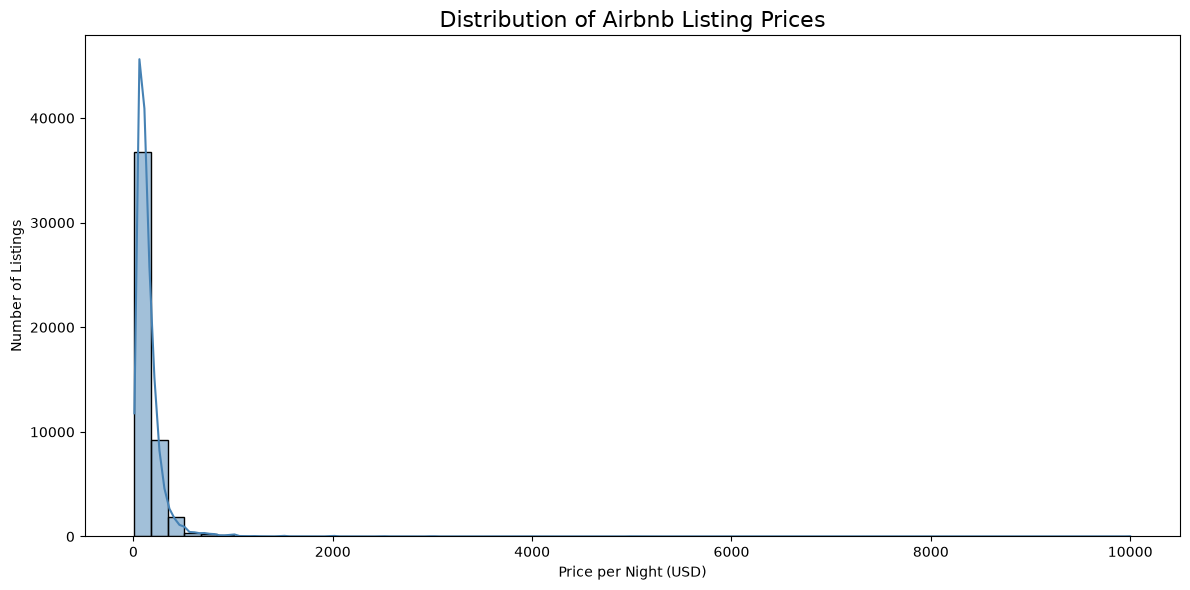

In [30]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_clean,
    x="price",
    bins=60,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Airbnb Listing Prices", fontsize=16)
plt.xlabel("Price per Night (USD)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()


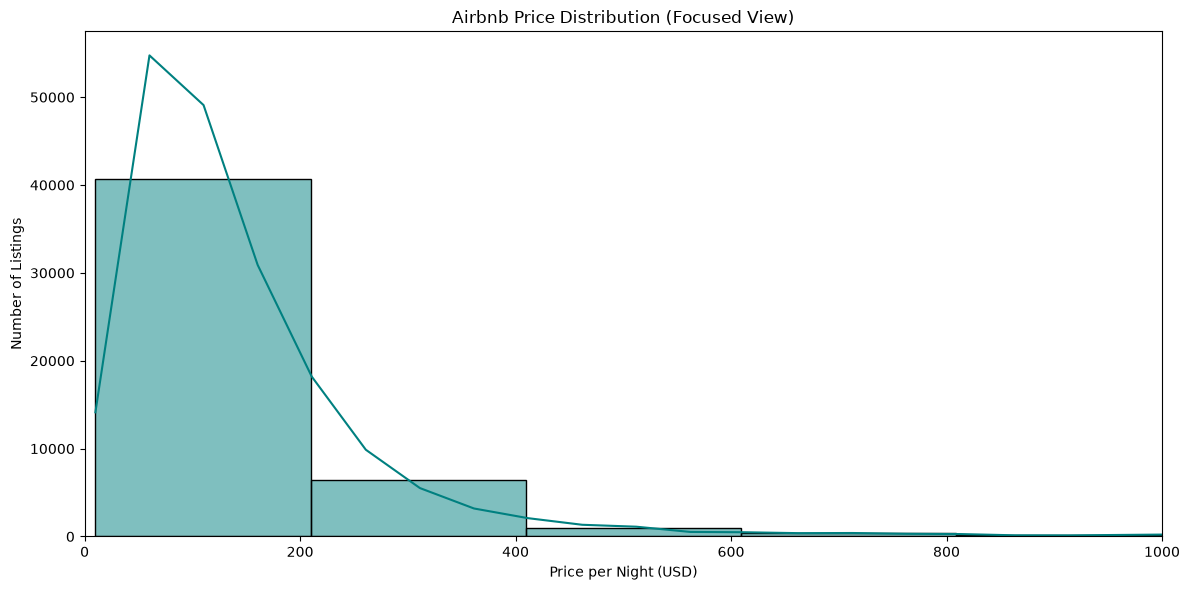

In [31]:

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_clean,
    x="price",
    bins=50,
    kde=True,
    color="teal"
)

plt.xlim(0, 1000)

plt.title("Airbnb Price Distribution (Focused View)")
plt.xlabel("Price per Night (USD)")
plt.ylabel("Number of Listings")

plt.tight_layout()
plt.show()


In [32]:

print("Mean Price:", round(df_clean["price"].mean(), 2))

print("Median Price:", df_clean["price"].median())

print("Price Skewness:", round(df_clean["price"].skew(), 2))


Mean Price: 152.76
Median Price: 106.0
Price Skewness: 19.12


In [33]:

borough_prices = df_clean.groupby(
    "neighbourhood_group"
)["price"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

borough_prices = borough_prices.sort_values(
    by="median",
    ascending=False
)

display(borough_prices)


,count,mean,median,min,max
neighbourhood_group,,,,,
Manhattan,21660,196.88,150.0,10,10000
Brooklyn,20095,124.44,90.0,10,10000
Queens,5666,99.52,75.0,10,10000
Staten Island,373,114.81,75.0,13,5000
Bronx,1090,87.58,65.0,10,2500


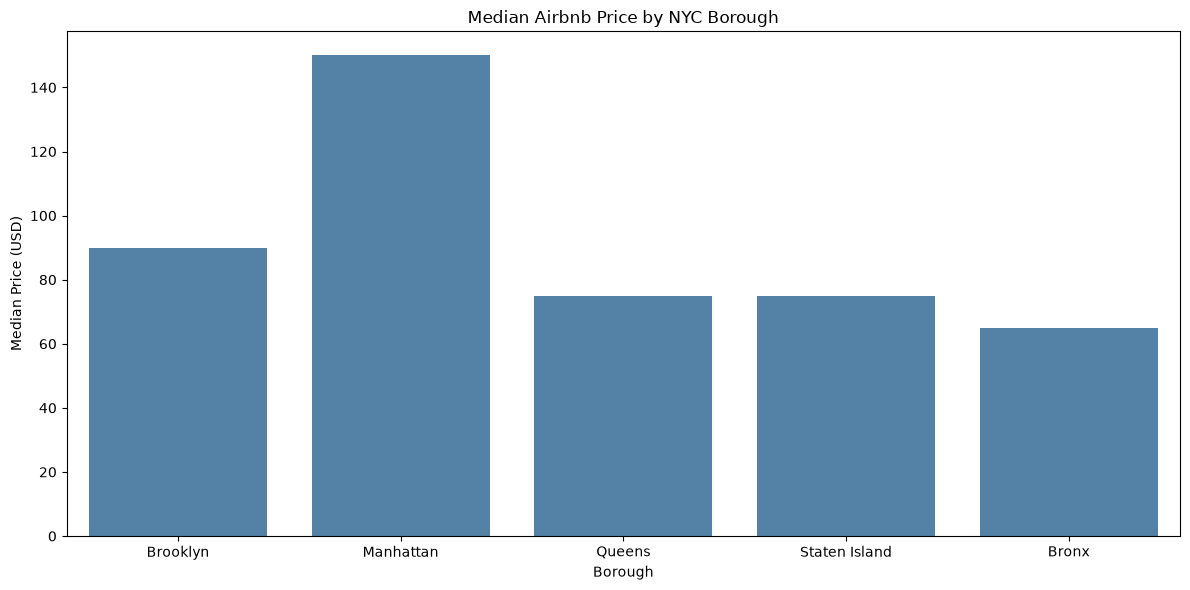

In [34]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_clean,
    x="neighbourhood_group",
    y="price",
    estimator=np.median,
    errorbar=None,
    color="steelblue"
)

plt.title("Median Airbnb Price by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Median Price (USD)")

plt.tight_layout()
plt.show()


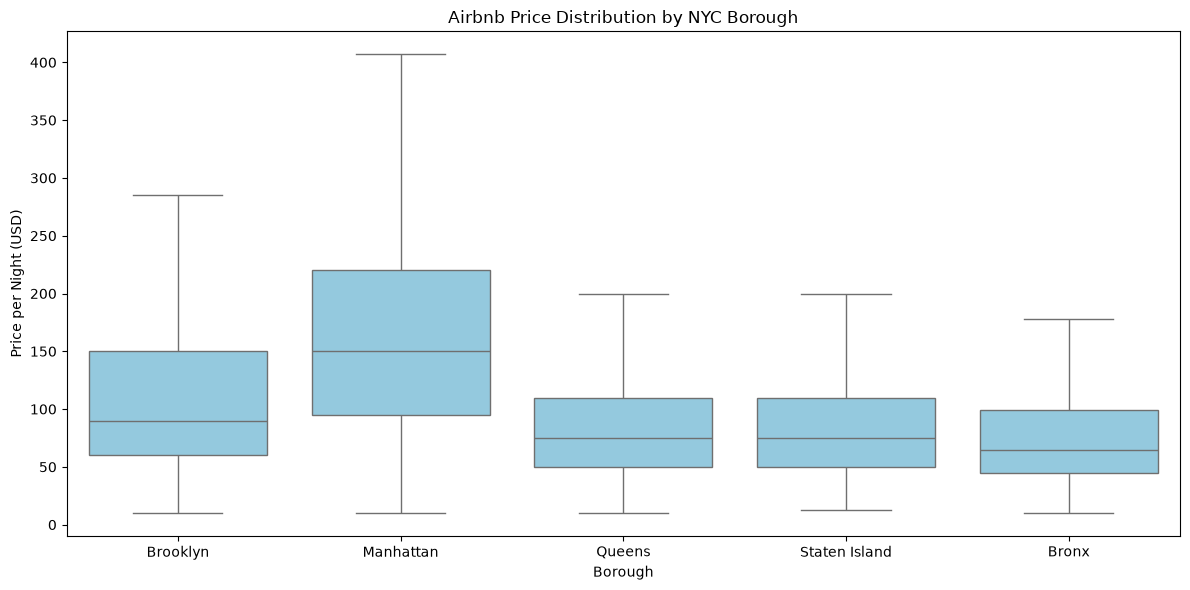

In [35]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_clean,
    x="neighbourhood_group",
    y="price",
    showfliers=False,
    color="skyblue"
)

plt.title("Airbnb Price Distribution by NYC Borough")
plt.xlabel("Borough")
plt.ylabel("Price per Night (USD)")

plt.tight_layout()
plt.show()


In [36]:

room_prices = df_clean.groupby("room_type")["price"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

room_prices = room_prices.sort_values(
    by="median",
    ascending=False
)

display(room_prices)


,count,mean,median,min,max
room_type,,,,,
Entire home/apt,25407,211.81,160.0,10,10000
Private room,22319,89.81,70.0,10,10000
Shared room,1158,70.25,45.0,10,1800


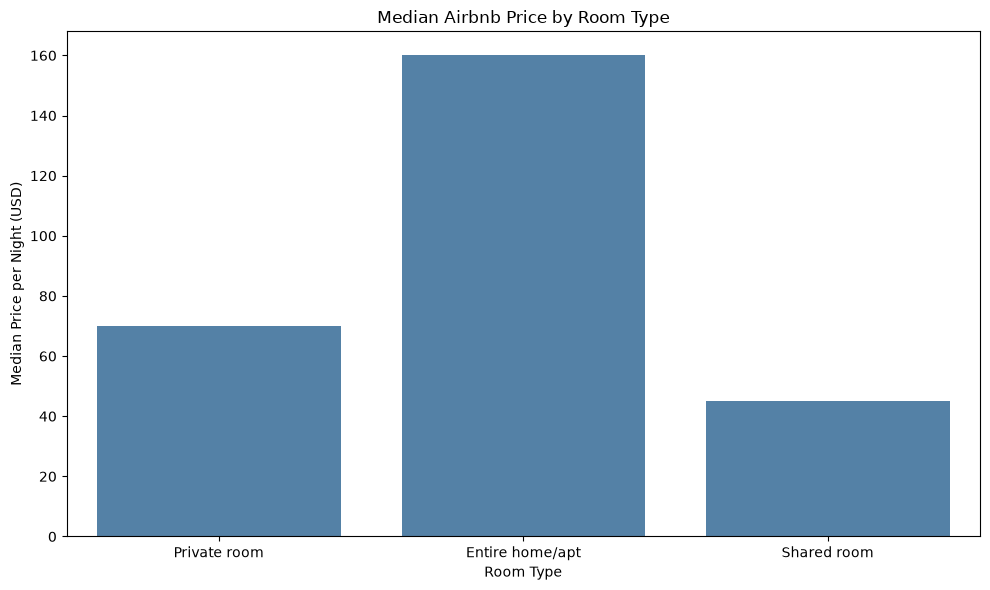

In [37]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_clean,
    x="room_type",
    y="price",
    estimator=np.median,
    errorbar=None,
    color="steelblue"
)

plt.title("Median Airbnb Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Median Price per Night (USD)")

plt.tight_layout()
plt.show()


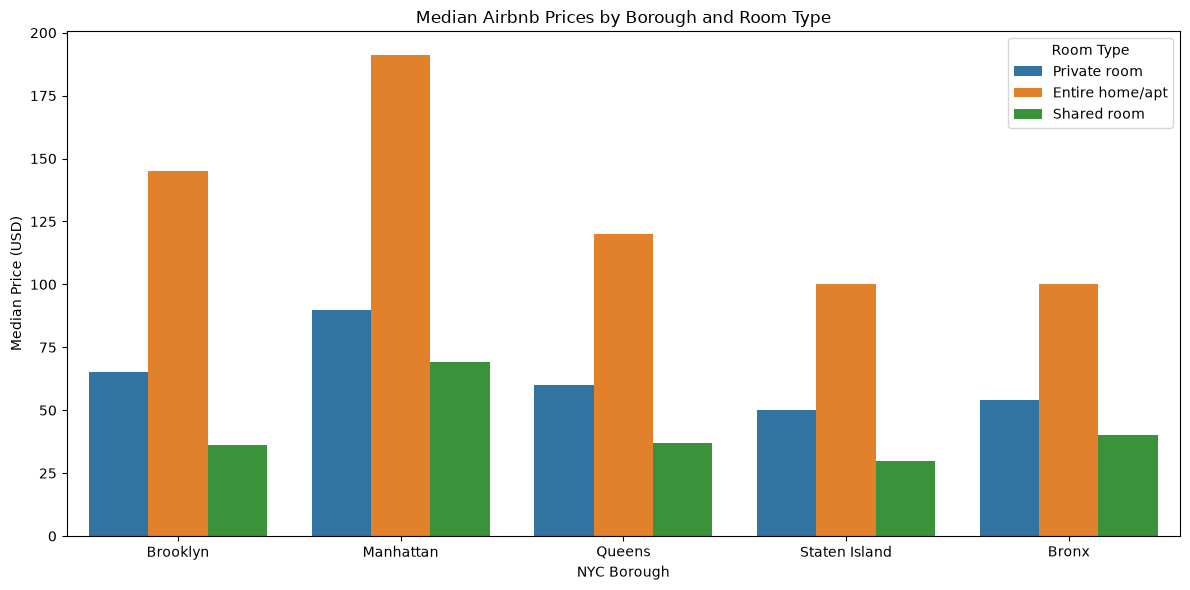

In [38]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_clean,
    x="neighbourhood_group",
    y="price",
    hue="room_type",
    estimator=np.median,
    errorbar=None
)

plt.title("Median Airbnb Prices by Borough and Room Type")
plt.xlabel("NYC Borough")
plt.ylabel("Median Price (USD)")
plt.legend(title="Room Type")

plt.tight_layout()
plt.show()


In [39]:

room_analysis = df_clean.groupby("room_type").agg(
    total_listings=("id", "count"),
    average_price=("price", "mean"),
    median_price=("price", "median")
).round(2)

display(room_analysis)


,total_listings,average_price,median_price
room_type,,,
Entire home/apt,25407,211.81,160.0
Private room,22319,89.81,70.0
Shared room,1158,70.25,45.0


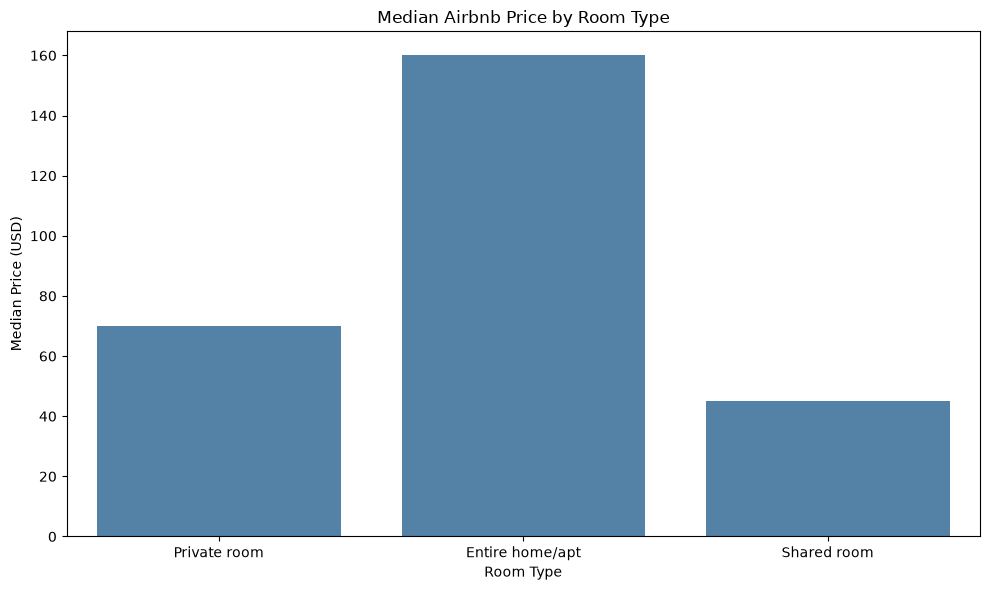

In [40]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_clean,
    x="room_type",
    y="price",
    estimator=np.median,
    errorbar=None,
    color="steelblue"
)

plt.title("Median Airbnb Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Median Price (USD)")

plt.tight_layout()
plt.show()


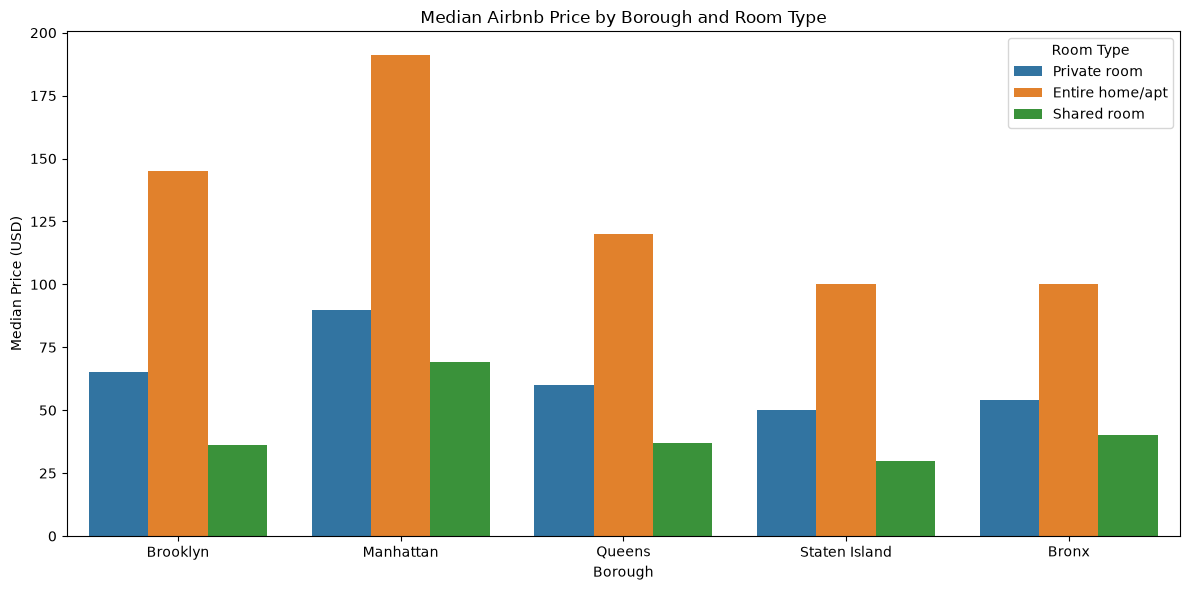

In [41]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_clean,
    x="neighbourhood_group",
    y="price",
    hue="room_type",
    estimator=np.median,
    errorbar=None
)

plt.title("Median Airbnb Price by Borough and Room Type")
plt.xlabel("Borough")
plt.ylabel("Median Price (USD)")
plt.legend(title="Room Type")

plt.tight_layout()
plt.show()


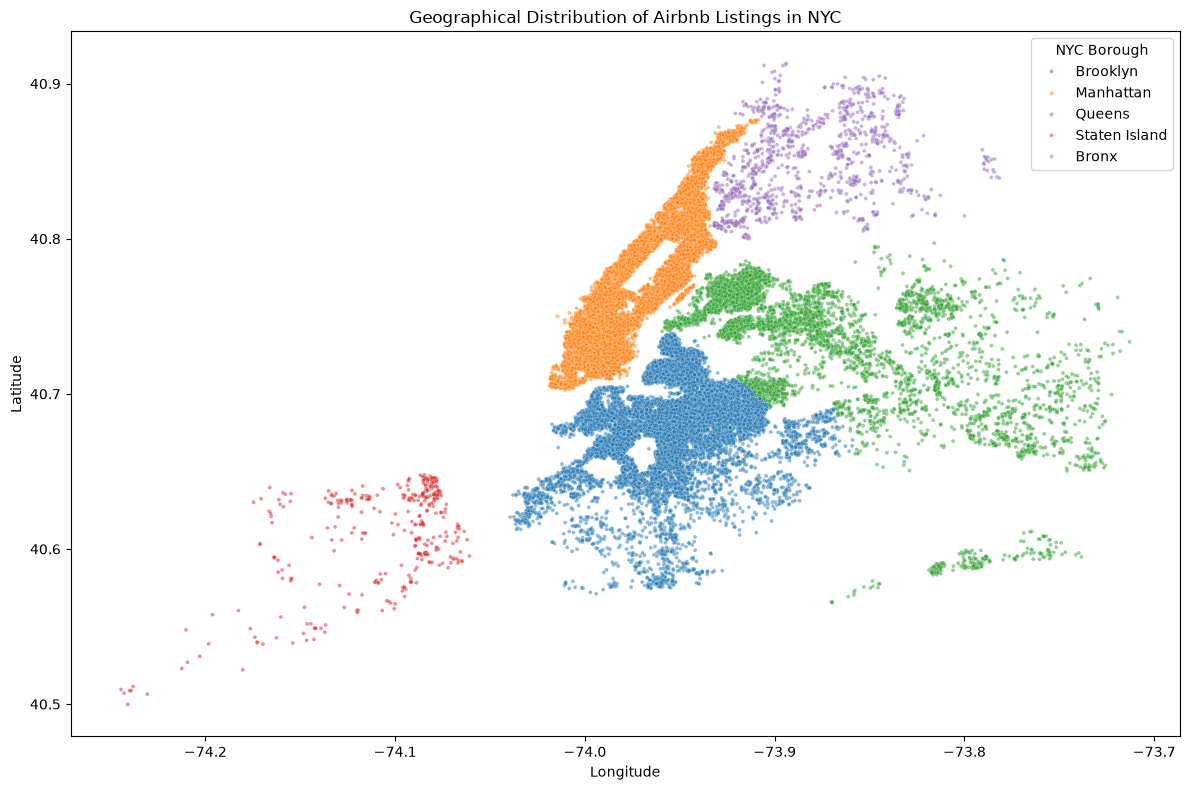

In [42]:

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df_clean,
    x="longitude",
    y="latitude",
    hue="neighbourhood_group",
    s=8,
    alpha=0.5
)

plt.title("Geographical Distribution of Airbnb Listings in NYC")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="NYC Borough")

plt.tight_layout()
plt.show()


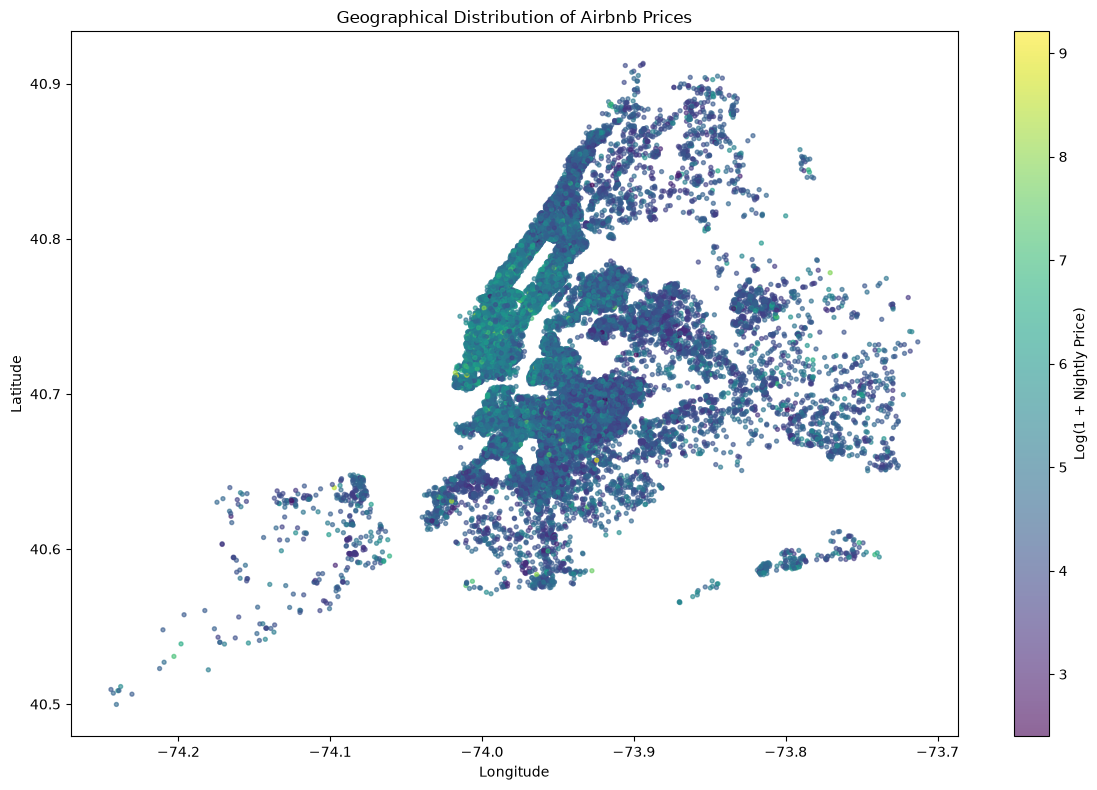

In [43]:

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df_clean["longitude"],
    df_clean["latitude"],
    c=np.log1p(df_clean["price"]),
    cmap="viridis",
    s=8,
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Log(1 + Nightly Price)"
)

plt.title("Geographical Distribution of Airbnb Prices")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()


In [44]:

borough_counts = df_clean[
    "neighbourhood_group"
].value_counts()

display(
    borough_counts.to_frame("Total Listings")
)


,Total Listings
neighbourhood_group,
Manhattan,21660
Brooklyn,20095
Queens,5666
Bronx,1090
Staten Island,373


## 16.1 Relationship Between Reviews and Airbnb Prices

In [45]:

review_analysis = df_clean.groupby("has_reviews").agg(
    total_listings=("id", "count"),
    average_price=("price", "mean"),
    median_price=("price", "median"),
    average_availability=("availability_365", "mean")
).round(2)

display(review_analysis)


,total_listings,average_price,median_price,average_availability
has_reviews,,,,
0,10051,192.94,120.0,104.67
1,38833,142.35,101.0,114.88


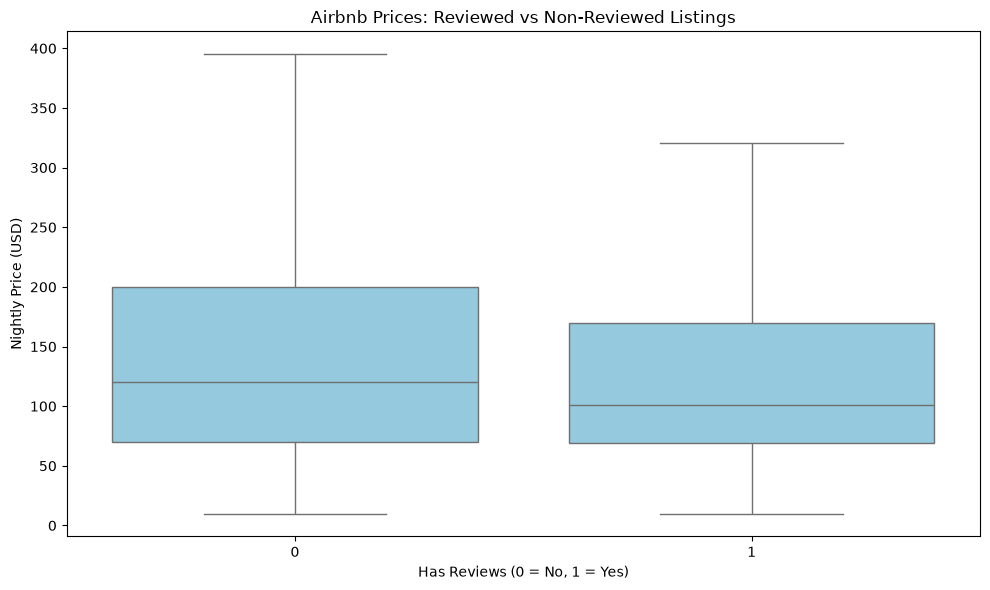

In [46]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="has_reviews",
    y="price",
    showfliers=False,
    color="skyblue"
)

plt.title("Airbnb Prices: Reviewed vs Non-Reviewed Listings")
plt.xlabel("Has Reviews (0 = No, 1 = Yes)")
plt.ylabel("Nightly Price (USD)")

plt.tight_layout()
plt.show()


In [47]:

availability_analysis = df_clean.groupby(
    "availability_category",
    observed=True
).agg(
    total_listings=("id", "count"),
    median_price=("price", "median"),
    average_price=("price", "mean")
).round(2)

display(availability_analysis)


,total_listings,median_price,average_price
availability_category,,,
Unavailable,17530,100.0,136.06
Low Availability,11711,100.0,142.21
Medium Availability,5282,110.0,161.53
High Availability,14361,120.0,178.51


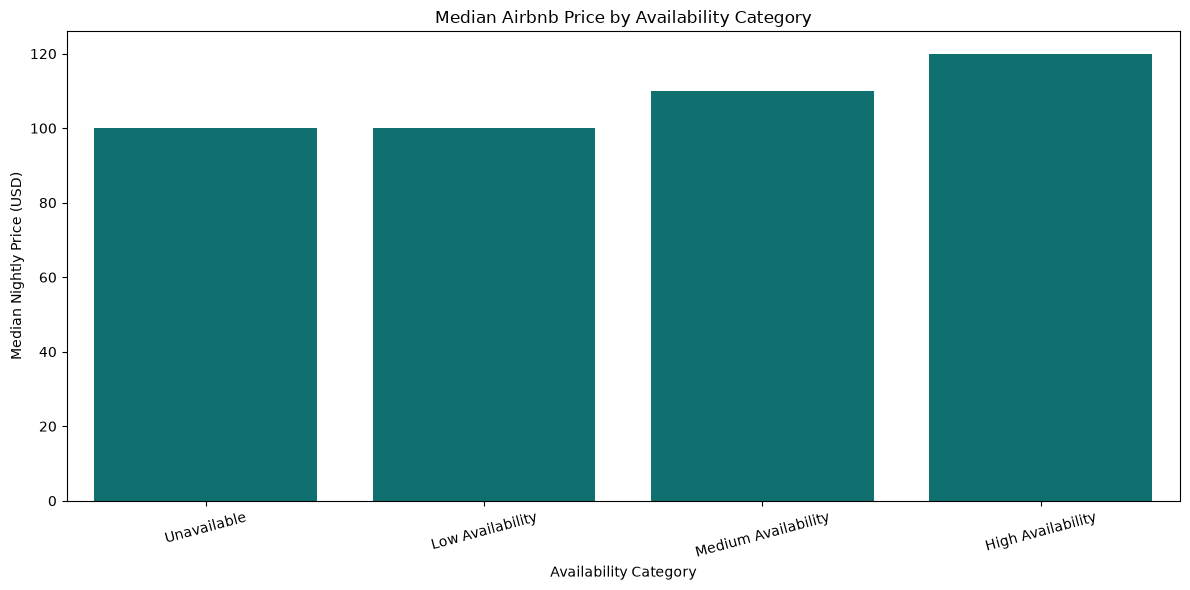

In [48]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_clean,
    x="availability_category",
    y="price",
    estimator=np.median,
    errorbar=None,
    color="teal"
)

plt.title("Median Airbnb Price by Availability Category")
plt.xlabel("Availability Category")
plt.ylabel("Median Nightly Price (USD)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


In [49]:

print("Minimum Nights Statistics:")

display(
    df_clean["minimum_nights"].describe()
)

print(
    "\nCorrelation Between Minimum Nights and Price:",
    round(
        df_clean["minimum_nights"].corr(df_clean["price"]),
        3
    )
)


Minimum Nights Statistics:


count    48884.000000
mean         7.029887
std         20.512224
min          1.000000
25%          1.000000
50%          3.000000
75%          5.000000
max       1250.000000
Name: minimum_nights, dtype: float64


Correlation Between Minimum Nights and Price: 0.043


## 17. Advanced Correlation Analysis

Objective: Identify relationships between numerical
features and Airbnb listing prices.

In [50]:

numeric_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "latitude",
    "longitude"
]

numeric_df = df_clean[numeric_columns]

display(numeric_df.head())


,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude
0,149,1,9,0.21,6,365,40.64749,-73.97237
1,225,1,45,0.38,2,355,40.75362,-73.98377
2,150,3,0,0.00,1,365,40.80902,-73.94190
3,89,1,270,4.64,1,194,40.68514,-73.95976
4,80,10,9,0.10,1,0,40.79851,-73.94399


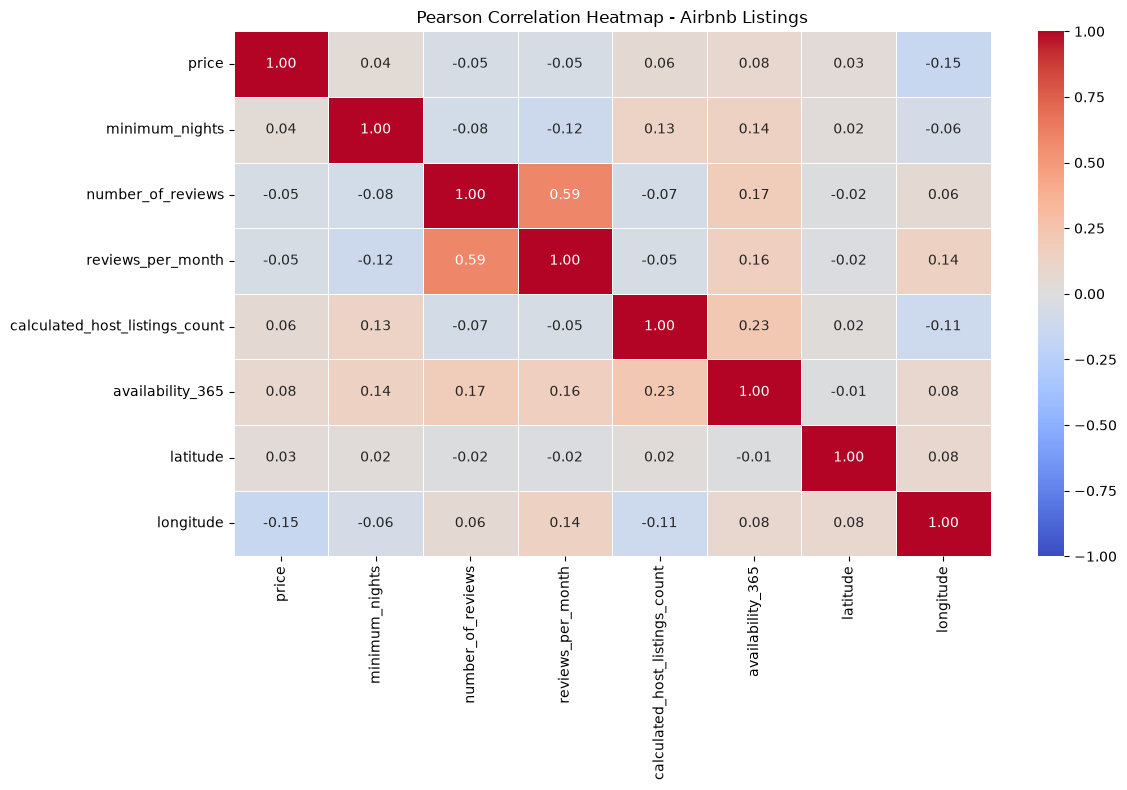

In [51]:

pearson_corr = numeric_df.corr(method="pearson")

plt.figure(figsize=(12, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Heatmap - Airbnb Listings")

plt.tight_layout()
plt.show()


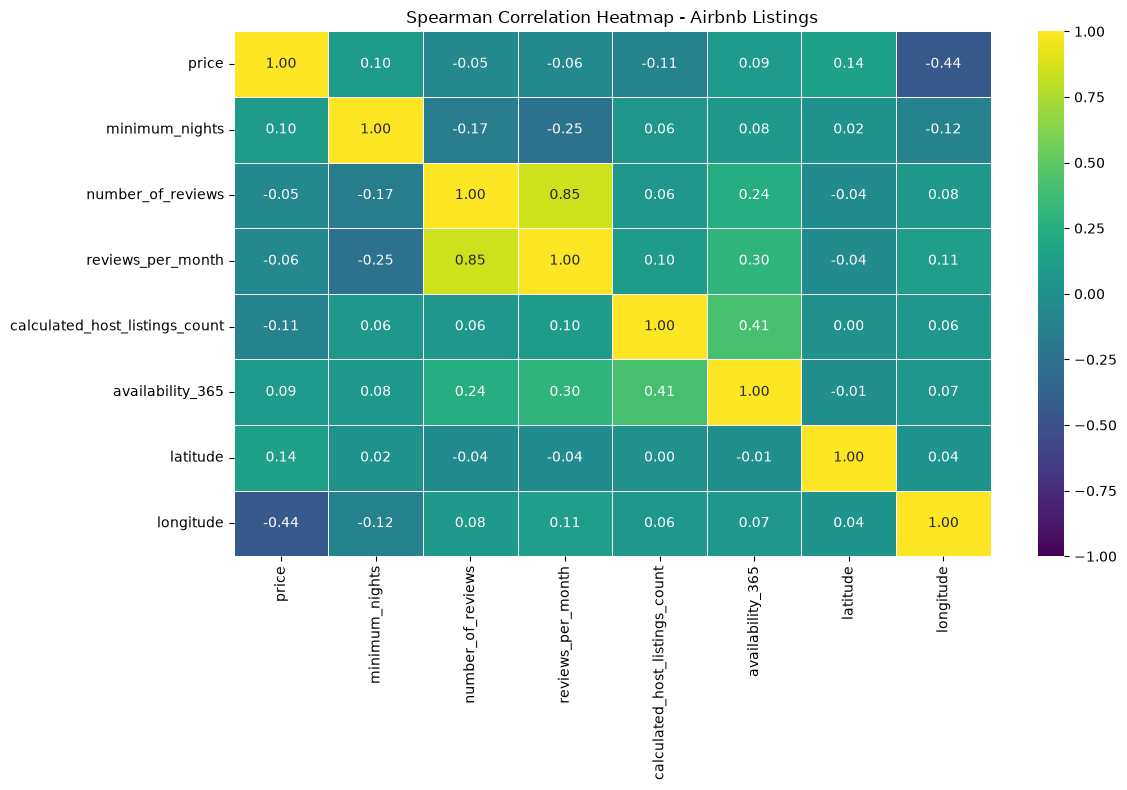

In [52]:

spearman_corr = numeric_df.corr(method="spearman")

plt.figure(figsize=(12, 8))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="viridis",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Heatmap - Airbnb Listings")

plt.tight_layout()
plt.show()


In [53]:

correlation_comparison = pd.DataFrame({
    "Pearson": pearson_corr["price"],
    "Spearman": spearman_corr["price"]
})

correlation_comparison = (
    correlation_comparison
    .drop(index="price")
    .sort_values(
        by="Spearman",
        key=lambda x: x.abs(),
        ascending=False
    )
)

display(correlation_comparison.round(3))


,Pearson,Spearman
longitude,-0.150,-0.438
latitude,0.034,0.136
calculated_host_listings_count,0.057,-0.106
minimum_nights,0.043,0.101
availability_365,0.082,0.086
reviews_per_month,-0.051,-0.060
number_of_reviews,-0.048,-0.055


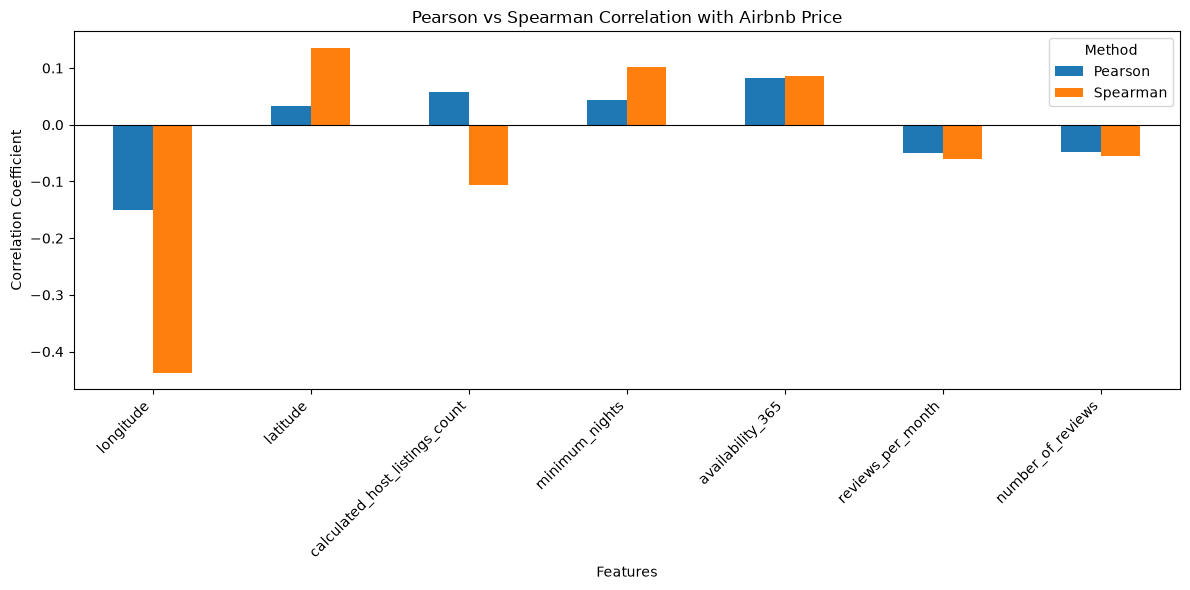

In [54]:

correlation_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Pearson vs Spearman Correlation with Airbnb Price")
plt.xlabel("Features")
plt.ylabel("Correlation Coefficient")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Method")

plt.tight_layout()
plt.show()


In [55]:

df_clean["price_category"] = pd.qcut(
    df_clean["price"].rank(method="first"),
    q=4,
    labels=["Budget", "Standard", "Premium", "Luxury"]
)

display(df_clean["price_category"].value_counts())


price_category
Budget      12221
Standard    12221
Premium     12221
Luxury      12221
Name: count, dtype: int64

In [56]:

df_clean["stay_category"] = pd.cut(
    df_clean["minimum_nights"],
    bins=[0, 2, 7, 30, np.inf],
    labels=[
        "Short Stay",
        "Weekly Stay",
        "Monthly Stay",
        "Extended Stay"
    ]
)

display(df_clean["stay_category"].value_counts())


stay_category
Short Stay       24410
Weekly Stay      17143
Monthly Stay      6584
Extended Stay      747
Name: count, dtype: int64

In [58]:

from sklearn.metrics.pairwise import haversine_distances

# Approximate Times Square coordinates
times_square_lat = 40.7580
times_square_lon = -73.9855

listing_coords = np.radians(
    df_clean[["latitude", "longitude"]].to_numpy()
)

reference_coords = np.radians(
    [[times_square_lat, times_square_lon]]
)

df_clean["distance_to_times_square_km"] = (
    haversine_distances(
        listing_coords,
        reference_coords
    ).flatten() * 6371
)

display(
    df_clean[
        ["latitude", "longitude", "distance_to_times_square_km"]
    ].head()
)


,latitude,longitude,distance_to_times_square_km
0,40.64749,-73.97237,12.337898
1,40.75362,-73.98377,0.508366
2,40.80902,-73.94190,6.757240
3,40.68514,-73.95976,8.387034
4,40.79851,-73.94399,5.701496


In [59]:

features = [
    "price_category",
    "stay_category",
    "distance_to_times_square_km"
]

display(df_clean[features].head(10))

print("Updated Dataset Shape:", df_clean.shape)


,price_category,stay_category,distance_to_times_square_km
0,Premium,Short Stay,12.337898
1,Luxury,Short Stay,0.508366
2,Premium,Weekly Stay,6.757240
3,Standard,Short Stay,8.387034
4,Standard,Monthly Stay,5.701496
5,Luxury,Weekly Stay,1.449704
6,Budget,Extended Stay,8.290747
7,Standard,Short Stay,0.767636
8,Standard,Short Stay,5.105387
9,Premium,Short Stay,4.971807


Updated Dataset Shape: (48884, 23)


In [60]:

print("Final Missing Values Report")

missing_report = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

display(missing_report)


Final Missing Values Report


,Missing Count,Missing Percentage
id,0,0.00
name,0,0.00
host_id,0,0.00
host_name,0,0.00
neighbourhood_group,0,0.00
neighbourhood,0,0.00
latitude,0,0.00
longitude,0,0.00
room_type,0,0.00
price,0,0.00


In [61]:

print("Duplicate Rows:", df_clean.duplicated().sum())

print(
    "Duplicate Listing IDs:",
    df_clean["id"].duplicated().sum()
)

print("Dataset Shape:", df_clean.shape)


Duplicate Rows: 0
Duplicate Listing IDs: 0
Dataset Shape: (48884, 23)


In [62]:

validation_report = {
    "Invalid Prices": (df_clean["price"] <= 0).sum(),

    "Invalid Minimum Nights": (
        df_clean["minimum_nights"] < 1
    ).sum(),

    "Invalid Availability": (
        ~df_clean["availability_365"].between(0, 365)
    ).sum(),

    "Negative Reviews": (
        df_clean["number_of_reviews"] < 0
    ).sum(),

    "Negative Monthly Reviews": (
        df_clean["reviews_per_month"] < 0
    ).sum(),

    "Invalid Host Listing Counts": (
        df_clean["calculated_host_listings_count"] < 1
    ).sum(),

    "Duplicate IDs": df_clean["id"].duplicated().sum()
}

validation_df = pd.DataFrame(
    validation_report.items(),
    columns=["Validation Check", "Invalid Records"]
)

display(validation_df)


,Validation Check,Invalid Records
0,Invalid Prices,0
1,Invalid Minimum Nights,0
2,Invalid Availability,0
3,Negative Reviews,0
4,Negative Monthly Reviews,0
5,Invalid Host Listing Counts,0
6,Duplicate IDs,0


In [63]:

engineered_features = [
    "has_reviews",
    "host_category",
    "availability_category",
    "price_category",
    "stay_category",
    "distance_to_times_square_km"
]

display(
    df_clean[engineered_features]
    .isnull()
    .sum()
    .to_frame("Missing Values")
)

print(
    "Negative Distances:",
    (df_clean["distance_to_times_square_km"] < 0).sum()
)


,Missing Values
has_reviews,0
host_category,0
availability_category,0
price_category,0
stay_category,0
distance_to_times_square_km,0


Negative Distances: 0


In [64]:

total_errors = sum(validation_report.values())

engineered_errors = (
    df_clean[engineered_features].isnull().sum().sum()
)

if total_errors == 0 and engineered_errors == 0:
    print("SUCCESS: All validation checks passed!")
else:
    print("WARNING: Data quality issues detected.")
    print("Invalid records:", total_errors)
    print("Missing engineered values:", engineered_errors)

print("Final Rows:", df_clean.shape[0])
print("Final Columns:", df_clean.shape[1])


SUCCESS: All validation checks passed!
Final Rows: 48884
Final Columns: 23


In [65]:

# Save the cleaned dataset
df_clean.to_csv("Airbnb_Cleaned.csv", index=False)

print("Cleaned Airbnb dataset saved successfully!")
print("Total Rows:", df_clean.shape[0])
print("Total Columns:", df_clean.shape[1])


Cleaned Airbnb dataset saved successfully!
Total Rows: 48884
Total Columns: 23


In [66]:

# Load the saved dataset for verification
df_final = pd.read_csv("Airbnb_Cleaned.csv")

print("Saved Dataset Shape:", df_final.shape)

display(df_final.head())


Saved Dataset Shape: (48884, 23)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,...,reviews_per_month,calculated_host_listings_count,availability_365,price_outlier,has_reviews,host_category,availability_category,price_category,stay_category,distance_to_times_square_km
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,...,0.21,6,365,False,1,Medium Host,High Availability,Premium,Short Stay,12.337898
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,...,0.38,2,355,False,1,Small Host,High Availability,Luxury,Short Stay,0.508366
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,...,0.00,1,365,False,0,Single Listing,High Availability,Premium,Weekly Stay,6.757240
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,...,4.64,1,194,False,1,Single Listing,High Availability,Standard,Short Stay,8.387034
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,...,0.10,1,0,False,1,Single Listing,Unavailable,Standard,Monthly Stay,5.701496
